In [189]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
import os
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve


In [282]:
#df11 = pd.read_csv('/home/nikta/AML/project/AML_coursework/phase2_3/spatial folds/spatial_folds_1:1.csv')
#df15 = pd.read_csv('/home/nikta/AML/project/AML_coursework/phase2_3/spatial folds/spatial_folds_1:5.csv')
df11 = pd.read_csv('../phase2_3/spatial folds/spatial_folds_1:1.csv')
df15 = pd.read_csv('../phase2_3/spatial folds/spatial_folds_1:5.csv')
rndfld11 = pd.read_csv('../phase2_3/random folds/randomfolds_1:1.csv')

In [283]:
df11.shape
df11.columns
df11['label'].value_counts()
df11['taxon_id'].value_counts()
df11['name'].value_counts()
df11['fold_id'].value_counts()

fold_id
1    3188
2    3044
3    3004
4    2530
0    2056
Name: count, dtype: int64

In [284]:
df15.shape
df15.columns
df15['label'].value_counts()
df15['taxon_id'].value_counts()
df15['name'].value_counts()
df15['fold_id'].value_counts()

fold_id
0    9002
4    8527
3    8053
2    8014
1    7870
Name: count, dtype: int64

In [285]:
df11.columns

Index(['lat', 'lon', 'taxon_id', 'name', 'label', 'x', 'y', 'z', 'lat_block',
       'lon_block', 'spatial_block', 'fold_id'],
      dtype='object')

In [286]:
df11['fold_id'].value_counts()

fold_id
1    3188
2    3044
3    3004
4    2530
0    2056
Name: count, dtype: int64

In [287]:
df15['fold_id'].value_counts()

fold_id
0    9002
4    8527
3    8053
2    8014
1    7870
Name: count, dtype: int64

In [288]:
tab11 = pd.crosstab([df11['name'], df11['fold_id']], df11['label'])
tab11.columns = ['absence', 'presence']

In [289]:
tab15 = pd.crosstab([df15['name'], df15['fold_id']], df15['label'])
tab15.columns = ['absence', 'presence']

In [290]:
(tab11['presence'] <= 5).value_counts()
check2 = tab15['presence'].unstack()
(check2 >= 10).sum(axis=1)

#Aviceda subcristata            4
#Carpodacus erythrinus          5
#Dacnis cayana                  5
#Dendropsophus microcephalus    4
#Ploceus xanthops               4
#Poicephalus meyeri             4


name
Ambystoma texanum              3
Aviceda subcristata            4
Carpodacus erythrinus          5
Cassiculus melanicterus        3
Contia tenuis                  3
Curruca hortensis              3
Dacnis cayana                  5
Dendropsophus microcephalus    4
Enicurus leschenaulti          2
Napaeozapus insignis           3
Petroica rodinogaster          2
Ploceus xanthops               4
Poecilotriccus plumbeiceps     2
Poicephalus meyeri             4
Trioceros deremensis           1
dtype: int64

In [291]:
(tab15['presence'] <= 5).value_counts()
check = tab11['presence'].unstack()
(check >= 10).sum(axis=1)

#Aviceda subcristata            4
#Carpodacus erythrinus          5
#Dacnis cayana                  5
#Dendropsophus microcephalus    4
#Ploceus xanthops               4
#Poicephalus meyeri             4

species = ['Aviceda subcristata',
    'Carpodacus erythrinus',
    'Dacnis cayana',
    'Dendropsophus microcephalus',
    'Ploceus xanthops',
    'Poicephalus meyeri',
]

In [292]:
df11['name'].isin(species)

0         True
1         True
2         True
3         True
4         True
         ...  
13817    False
13818    False
13819    False
13820    False
13821    False
Name: name, Length: 13822, dtype: bool

In [293]:
df_sel = df11[df11['name'].isin(species)]
df_sel['name'].value_counts()

name
Carpodacus erythrinus          3718
Dacnis cayana                  1650
Dendropsophus microcephalus     658
Aviceda subcristata             658
Ploceus xanthops                344
Poicephalus meyeri              290
Name: count, dtype: int64

In [294]:
df_sel['label'].value_counts()

label
0    3659
1    3659
Name: count, dtype: int64

In [295]:
df_sel['label'].value_counts()
df_sel['fold_id'].value_counts()

fold_id
1    1836
2    1582
4    1455
3    1276
0    1169
Name: count, dtype: int64

In [296]:
pres = df_sel[df11['label'] == 1]

/tmp/ipykernel_60331/3737052906.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  pres = df_sel[df11['label'] == 1]


In [297]:

pres.groupby('name')[['lat', 'lon']].agg(['min', 'max'])

lat                    lon            
                                   min        max         min         max
name                                                                     
Aviceda subcristata         -35.034515  -1.073664  127.968870  158.000060
Carpodacus erythrinus        10.057477  66.037760 -176.586720  158.742460
Dacnis cayana               -29.884762  11.305075  -84.710180  -34.845566
Dendropsophus microcephalus  -9.555626  20.964280  -95.634320  -55.921566
Ploceus xanthops            -29.781834   1.097396   12.202220   37.067867
Poicephalus meyeri          -24.734398   6.602364   16.848402   37.149210

In [298]:
pres['name'].value_counts()

name
Carpodacus erythrinus          1859
Dacnis cayana                   825
Dendropsophus microcephalus     329
Aviceda subcristata             329
Ploceus xanthops                172
Poicephalus meyeri              145
Name: count, dtype: int64

In [299]:
def split_fold(df, spcs, fold):
    d = df[df['name'] == spcs]
    test  = d[d['fold_id'] == fold]
    train = d[d['fold_id'] != fold]
    X_train = train[['x', 'y', 'z']]
    Y_train = train['label']
    X_test  = test[['x', 'y', 'z']]
    Y_test  = test['label']
    if test['label'].nunique() < 2:
        return None
    if train['label'].nunique() < 2:
        return None
    return X_train, X_test, Y_train, Y_test


results = []
for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)
        if res is None:
            print(spcs, fold, 'nah')
        else:
            X_train, X_test, Y_train, Y_test = res
            p = Y_train.mean()
            dummy = np.full(len(Y_test), p)
            roc_auc = roc_auc_score(Y_test, dummy)
            avg_prc  = average_precision_score(Y_test, dummy)
            print(spcs, fold, len(X_train), len(X_test))
            results.append({'species': spcs, 'fold': fold, 'model': 'dummy', 'roc_auc': roc_auc, 'avg_prc': avg_prc})




print(results)
        

Aviceda subcristata 0 574 84
Aviceda subcristata 1 351 307
Aviceda subcristata 2 547 111
Aviceda subcristata 3 nah
Aviceda subcristata 4 562 96
Carpodacus erythrinus 0 3119 599
Carpodacus erythrinus 1 2676 1042
Carpodacus erythrinus 2 3095 623
Carpodacus erythrinus 3 3000 718
Carpodacus erythrinus 4 2982 736
Dacnis cayana 0 1409 241
Dacnis cayana 1 1357 293
Dacnis cayana 2 1149 501
Dacnis cayana 3 1353 297
Dacnis cayana 4 1332 318
Dendropsophus microcephalus 0 580 78
Dendropsophus microcephalus 1 549 109
Dendropsophus microcephalus 2 460 198
Dendropsophus microcephalus 3 556 102
Dendropsophus microcephalus 4 487 171
Ploceus xanthops 0 258 86
Ploceus xanthops 1 310 34
Ploceus xanthops 2 270 74
Ploceus xanthops 3 282 62
Ploceus xanthops 4 256 88
Poicephalus meyeri 0 209 81
Poicephalus meyeri 1 239 51
Poicephalus meyeri 2 215 75
Poicephalus meyeri 3 253 37
Poicephalus meyeri 4 244 46
[{'species': 'Aviceda subcristata', 'fold': 0, 'model': 'dummy', 'roc_auc': 0.5, 'avg_prc': 0.130952380952

In [300]:
#split_fold(df_sel, 'Dacnis cayana', 0)
res_df = pd.DataFrame(results)
print(res_df.to_string())

                        species  fold  model  roc_auc   avg_prc
0           Aviceda subcristata     0  dummy      0.5  0.130952
1           Aviceda subcristata     1  dummy      0.5  0.840391
2           Aviceda subcristata     2  dummy      0.5  0.423423
3           Aviceda subcristata     4  dummy      0.5  0.135417
4         Carpodacus erythrinus     0  dummy      0.5  0.240401
5         Carpodacus erythrinus     1  dummy      0.5  0.710173
6         Carpodacus erythrinus     2  dummy      0.5  0.455859
7         Carpodacus erythrinus     3  dummy      0.5  0.522284
8         Carpodacus erythrinus     4  dummy      0.5  0.429348
9                 Dacnis cayana     0  dummy      0.5  0.074689
10                Dacnis cayana     1  dummy      0.5  0.525597
11                Dacnis cayana     2  dummy      0.5  0.726547
12                Dacnis cayana     3  dummy      0.5  0.468013
13                Dacnis cayana     4  dummy      0.5  0.471698
14  Dendropsophus microcephalus     0  d

In [301]:
p = Y_train.mean()
print(p)

0.5286885245901639


In [302]:
dummy = np.full(len(Y_test), p)
print(dummy)

[0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852 0.52868852
 0.52868852 0.52868852 0.52868852 0.52868852]


In [303]:
roc_auc = roc_auc_score(Y_test, dummy)
avg_prc  = average_precision_score(Y_test, dummy)
print(roc_auc, avg_prc)

0.5 0.34782608695652173


In [304]:
print(res_df.groupby('species')[['roc_auc', 'avg_prc']].agg(['mean', 'std']))
os.makedirs('results', exist_ok=True)
res_df.to_csv('results/baseline_dummy.csv', index=False)

                            roc_auc        avg_prc          
                               mean  std      mean       std
species                                                     
Aviceda subcristata             0.5  0.0  0.382546  0.334497
Carpodacus erythrinus           0.5  0.0  0.471613  0.169538
Dacnis cayana                   0.5  0.0  0.453309  0.236533
Dendropsophus microcephalus     0.5  0.0  0.437300  0.242041
Ploceus xanthops                0.5  0.0  0.466536  0.148978
Poicephalus meyeri              0.5  0.0  0.455487  0.184763


In [305]:
results = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res

            model = DummyClassifier(strategy='prior')  
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            results.append({'species': spcs, 'fold': fold, 'model': 'dummy',
                            'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_dummy = pd.DataFrame(results)
print(len(res_dummy))
print(res_dummy.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 3 skipped


29
                             roc_auc   avg_prc
species                                       
Aviceda subcristata              0.5  0.382546
Carpodacus erythrinus            0.5  0.471613
Dacnis cayana                    0.5  0.453309
Dendropsophus microcephalus      0.5  0.437300
Ploceus xanthops                 0.5  0.466536
Poicephalus meyeri               0.5  0.455487


In [306]:
LG_results = []
for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            model = LogisticRegression(max_iter=1000, random_state=0)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            LG_results.append({'species': spcs, 'fold': fold, 'model': 'logreg',
                               'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_logreg = pd.DataFrame(LG_results)
print(len(res_logreg))
print(res_logreg.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 3 skipped
29
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.951959  0.897734
Carpodacus erythrinus        0.961585  0.924294
Dacnis cayana                0.957936  0.846578
Dendropsophus microcephalus  0.928813  0.868788
Ploceus xanthops             0.968612  0.898971
Poicephalus meyeri           0.981935  0.966305


In [307]:
print(X_train.columns.tolist())

['x', 'y', 'z']


In [308]:
print(set(X_train.index) & set(X_test.index))   

set()


In [309]:
print(res_logreg.to_string())

                        species  fold   model   roc_auc   avg_prc
0           Aviceda subcristata     0  logreg  0.986301  0.808799
1           Aviceda subcristata     1  logreg  0.896614  0.966919
2           Aviceda subcristata     2  logreg  0.982380  0.974229
3           Aviceda subcristata     4  logreg  0.942539  0.840990
4         Carpodacus erythrinus     0  logreg  0.955983  0.865762
5         Carpodacus erythrinus     1  logreg  0.956059  0.969746
6         Carpodacus erythrinus     2  logreg  0.965391  0.948585
7         Carpodacus erythrinus     3  logreg  0.965800  0.938785
8         Carpodacus erythrinus     4  logreg  0.964693  0.898590
9                 Dacnis cayana     0  logreg  0.973592  0.561321
10                Dacnis cayana     1  logreg  0.946604  0.911728
11                Dacnis cayana     2  logreg  0.956946  0.972177
12                Dacnis cayana     3  logreg  0.955195  0.865902
13                Dacnis cayana     4  logreg  0.957341  0.921764
14  Dendro

In [310]:
res_logreg.to_csv('results/log_reg.csv', index=False)


In [311]:
RF_results = []
for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            model = RandomForestClassifier(n_estimators=100, random_state=0)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            RF_results.append({'species': spcs, 'fold': fold, 'model': 'rf',
                               'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_rf = pd.DataFrame(RF_results)
print(len(res_rf))
print(res_rf.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 3 skipped
29
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.961829  0.932415
Carpodacus erythrinus        0.957941  0.922359
Dacnis cayana                0.976637  0.954145
Dendropsophus microcephalus  0.982561  0.963108
Ploceus xanthops             0.986220  0.986904
Poicephalus meyeri           0.991754  0.990687


In [312]:
res_rf.to_csv('results/rf.csv', index=False)

In [313]:
t_res = pd.concat([res_dummy, res_logreg, res_rf])
print(t_res.groupby(['species', 'model'])[['roc_auc', 'avg_prc']].agg(['mean', 'std']))
res_rf.to_csv('results/rf.csv', index=False)

                                     roc_auc             avg_prc          
                                        mean       std      mean       std
species                     model                                         
Aviceda subcristata         dummy   0.500000  0.000000  0.382546  0.334497
                            logreg  0.951959  0.041859  0.897734  0.085181
                            rf      0.961829  0.052256  0.932415  0.058900
Carpodacus erythrinus       dummy   0.500000  0.000000  0.471613  0.169538
                            logreg  0.961585  0.005095  0.924294  0.041691
                            rf      0.957941  0.018118  0.922359  0.062991
Dacnis cayana               dummy   0.500000  0.000000  0.453309  0.236533
                            logreg  0.957936  0.009777  0.846578  0.163873
                            rf      0.976637  0.016590  0.954145  0.027967
Dendropsophus microcephalus dummy   0.500000  0.000000  0.437300  0.242041
                         

roc_auc             avg_prc          
                                        mean       std      mean       std
species                     model                                         
Aviceda subcristata         dummy   0.500000  0.000000  0.382546  0.334497
                            logreg  0.951959  0.041859  0.897734  0.085181
                            rf      0.961829  0.052256  0.932415  0.058900
Carpodacus erythrinus       dummy   0.500000  0.000000  0.471613  0.169538
                            logreg  0.961585  0.005095  0.924294  0.041691
                            rf      0.957941  0.018118  0.922359  0.062991
*Dacnis cayana               dummy   0.500000  0.000000  0.453309  0.236533
                            logreg  0.957936  0.009777  0.846578  0.163873
                            *rf      0.976637  0.016590  0.954145  0.027967
*Dendropsophus microcephalus dummy   0.500000  0.000000  0.437300  0.242041
                            logreg  0.928813  0.061513  0.868788  0.117805
                            rf      0.982561  0.009061  0.963108  0.021994
*Ploceus xanthops            dummy   0.500000  0.000000  0.466536  0.148978
                            *logreg  0.968612  0.022227  0.898971  0.145035
                            rf      0.986220  0.015004  0.986904  0.012868
Poicephalus meyeri          dummy   0.500000  0.000000  0.455487  0.184763
                            logreg  0.981935  0.030682  0.966305  0.067574
                            rf      0.991754  0.018438  0.990687  0.020825

In [314]:
t_res.to_csv('results/all_models.csv', index=False)

In [315]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn_res = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res

            model = KNeighborsClassifier(n_neighbors=5)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            knn_res.append({'species': spcs, 'fold': fold, 'model': 'knn',
                            'roc_auc': roc_auc, 'avg_prc': avg_prc})

knn_results = pd.DataFrame(knn_res)
print(len(knn_results))
print(knn_results.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 3 skipped
29
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.876155  0.847608
Carpodacus erythrinus        0.932215  0.885363
Dacnis cayana                0.963291  0.937697
Dendropsophus microcephalus  0.979914  0.926737
Ploceus xanthops             0.974740  0.941053
Poicephalus meyeri           0.986322  0.975990


In [316]:
knn_results.to_csv('results/knn.csv', index=False)

In [317]:
res_all = pd.concat([res_dummy, res_logreg, res_rf, knn_results])
print(res_all.groupby(['species', 'model'])[['roc_auc', 'avg_prc']].agg(['mean', 'std']))
res_all.to_csv('results/all_models.csv', index=False)

                                     roc_auc             avg_prc          
                                        mean       std      mean       std
species                     model                                         
Aviceda subcristata         dummy   0.500000  0.000000  0.382546  0.334497
                            knn     0.876155  0.181652  0.847608  0.200932
                            logreg  0.951959  0.041859  0.897734  0.085181
                            rf      0.961829  0.052256  0.932415  0.058900
Carpodacus erythrinus       dummy   0.500000  0.000000  0.471613  0.169538
                            knn     0.932215  0.041714  0.885363  0.094805
                            logreg  0.961585  0.005095  0.924294  0.041691
                            rf      0.957941  0.018118  0.922359  0.062991
Dacnis cayana               dummy   0.500000  0.000000  0.453309  0.236533
                            knn     0.963291  0.034419  0.937697  0.032715
                         

In [318]:
len(res_all)

116

In [319]:
print(knn_results[knn_results['species'] == 'Aviceda subcristata'])

               species  fold model   roc_auc   avg_prc
0  Aviceda subcristata     0   knn  1.000000  1.000000
1  Aviceda subcristata     1   knn  0.905632  0.965397
2  Aviceda subcristata     2   knn  0.611037  0.558367
3  Aviceda subcristata     4   knn  0.987952  0.866667


In [320]:
rndfld11 = pd.read_csv('/home/nikta/AML/project/AML_coursework/phase2_3/random folds/randomfolds_1:1.csv')

In [321]:
rndfld11.columns
rndfld11 = rndfld11.drop(['fold_id'], axis=1)

In [322]:
rndfld11.columns

Index(['lat', 'lon', 'taxon_id', 'name', 'label', 'x', 'y', 'z', 'lat_block',
       'lon_block', 'spatial_block', 'random_fold_id'],
      dtype='object')

In [323]:
rndfld11 = rndfld11.rename(columns={'random_fold_id': 'fold_id'})

In [324]:
rndfld11_spcs = rndfld11[rndfld11['name'].isin(species)]
print(rndfld11_spcs['fold_id'].value_counts())      

fold_id
3    1503
2    1497
1    1448
4    1446
0    1424
Name: count, dtype: int64


In [325]:
print(rndfld11_spcs['label'].value_counts())        
print(len(rndfld11_spcs), len(df_sel)) 

label
0    3659
1    3659
Name: count, dtype: int64
7318 7318


In [326]:
RFR_results = []
for spcs in species:
    for fold in range(5):
        res = split_fold(rndfld11_spcs, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            model = RandomForestClassifier(n_estimators=100, random_state=0)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            RFR_results.append({'species': spcs, 'fold': fold, 'model': 'rf_random',
                                'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_rf_random = pd.DataFrame(RFR_results)
print(len(res_rf_random))
print(res_rf_random.groupby('species')[['roc_auc', 'avg_prc']].agg(['mean', 'std']))

30
                              roc_auc             avg_prc          
                                 mean       std      mean       std
species                                                            
Aviceda subcristata          0.979706  0.005974  0.961977  0.010258
Carpodacus erythrinus        0.979584  0.005379  0.966460  0.009907
Dacnis cayana                0.983294  0.004609  0.969960  0.007553
Dendropsophus microcephalus  0.988281  0.012735  0.980701  0.022867
Ploceus xanthops             0.987497  0.016390  0.977509  0.031796
Poicephalus meyeri           0.992367  0.010491  0.980951  0.026104


In [327]:
res = split_fold(df_sel, 'Dacnis cayana', 0)
X_train, X_test, Y_train, Y_test = res

X_pres = X_train[Y_train == 1]          

nn = NearestNeighbors(n_neighbors=1)
nn.fit(X_pres)

dist, _ = nn.kneighbors(X_test)       
scores = -dist[:, 0]

print(roc_auc_score(Y_test, scores))
print(average_precision_score(Y_test, scores))

0.9860488290981565
0.7856752843101387


In [328]:
NN_results = []
for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            X_pres = X_train[Y_train == 1]
            nn = NearestNeighbors(n_neighbors=1)
            nn.fit(X_pres)
            dist, _ = nn.kneighbors(X_test)
            scores = -dist[:, 0]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            NN_results.append({'species': spcs, 'fold': fold, 'model': 'nn_dist',
                               'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_nn = pd.DataFrame(NN_results)
print(len(res_nn))
print(res_nn.groupby('species')[['roc_auc', 'avg_prc']].agg(['mean', 'std']))
res_nn.to_csv('results/nn_dist.csv', index=False)

Aviceda subcristata 3 skipped
29
                              roc_auc             avg_prc          
                                 mean       std      mean       std
species                                                            
Aviceda subcristata          0.953007  0.042978  0.860875  0.239603
Carpodacus erythrinus        0.936364  0.049787  0.890102  0.110829
Dacnis cayana                0.957635  0.048962  0.908180  0.073473
Dendropsophus microcephalus  0.976533  0.015259  0.967263  0.018667
Ploceus xanthops             0.970765  0.029073  0.905974  0.160982
Poicephalus meyeri           0.990855  0.020450  0.989970  0.022427


In [329]:
res_all = pd.concat([res_dummy, res_nn, res_logreg, res_rf, knn_results])
print(len(res_all))  

145


In [330]:
print(res_all.groupby(['species', 'model'])[['roc_auc', 'avg_prc']].agg(['mean', 'std']))
res_all.to_csv('results/all_models.csv', index=False)

                                      roc_auc             avg_prc          
                                         mean       std      mean       std
species                     model                                          
Aviceda subcristata         dummy    0.500000  0.000000  0.382546  0.334497
                            knn      0.876155  0.181652  0.847608  0.200932
                            logreg   0.951959  0.041859  0.897734  0.085181
                            nn_dist  0.953007  0.042978  0.860875  0.239603
                            rf       0.961829  0.052256  0.932415  0.058900
Carpodacus erythrinus       dummy    0.500000  0.000000  0.471613  0.169538
                            knn      0.932215  0.041714  0.885363  0.094805
                            logreg   0.961585  0.005095  0.924294  0.041691
                            nn_dist  0.936364  0.049787  0.890102  0.110829
                            rf       0.957941  0.018118  0.922359  0.062991
Dacnis cayan

In [331]:
len(res_all)

145

In [332]:
print(os.listdir('results'))

['knn_k15.csv', 'roc_Ploceus xanthops.png', 'baseline_dummy.csv', 'roc_Poicephalus_meyeri.png', 'nn_dist.csv', 'roc_Aviceda_subcristata.png', 'hard_negatives.csv', 'roc_Dendropsophus microcephalus.png', 'roc_models_dacnis_fold0.png', 'roc_Carpodacus_erythrinus.png', 'roc_Dacnis cayana.png', 'roc_Aviceda subcristata.png', 'knn_nested.csv', 'roc_Ploceus_xanthops.png', 'rf_random.csv', 'roc_Dendropsophus_microcephalus.png', 'log_reg.csv', 'roc_Dacnis_cayana.png', 'roc_Poicephalus meyeri.png', 'rf_seeds.csv', 'knn.csv', 'rf.csv', 'all_models_final.csv', 'preds_rf.csv', 'knn_tuning.csv', 'roc_Carpodacus erythrinus.png', 'all_models.csv']


In [333]:
res_rf_random.to_csv('results/rf_random.csv', index=False)
print(os.listdir('results'))

['knn_k15.csv', 'roc_Ploceus xanthops.png', 'baseline_dummy.csv', 'roc_Poicephalus_meyeri.png', 'nn_dist.csv', 'roc_Aviceda_subcristata.png', 'hard_negatives.csv', 'roc_Dendropsophus microcephalus.png', 'roc_models_dacnis_fold0.png', 'roc_Carpodacus_erythrinus.png', 'roc_Dacnis cayana.png', 'roc_Aviceda subcristata.png', 'knn_nested.csv', 'roc_Ploceus_xanthops.png', 'rf_random.csv', 'roc_Dendropsophus_microcephalus.png', 'log_reg.csv', 'roc_Dacnis_cayana.png', 'roc_Poicephalus meyeri.png', 'rf_seeds.csv', 'knn.csv', 'rf.csv', 'all_models_final.csv', 'preds_rf.csv', 'knn_tuning.csv', 'roc_Carpodacus erythrinus.png', 'all_models.csv']


In [334]:
RF_results = []
pred_parts = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_sel, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            model = RandomForestClassifier(n_estimators=100, random_state=0)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            part = pd.DataFrame({
                'species': spcs,
                'fold': fold,
                'model': 'rf',
                'lat': df_sel.loc[X_test.index, 'lat'].values,
                'lon': df_sel.loc[X_test.index, 'lon'].values,
                'y_true': Y_test.values,
                'score': scores,
            })
            pred_parts.append(part)

preds_rf = pd.concat(pred_parts, ignore_index=True)
preds_rf.to_csv('results/preds_rf.csv', index=False)

Aviceda subcristata 3 skipped


In [335]:
print(len(preds_rf))
print(preds_rf.head())

7258
               species  fold model        lat         lon  y_true  score
0  Aviceda subcristata     0    rf -14.181800  132.189600       1    0.4
1  Aviceda subcristata     0    rf  33.060936 -115.681050       0    0.0
2  Aviceda subcristata     0    rf  44.113625    6.006127       0    0.0
3  Aviceda subcristata     0    rf  36.602303 -112.348820       0    0.0
4  Aviceda subcristata     0    rf  32.739662 -117.067730       0    0.0


In [336]:
tune = []

for k_nn in [1, 3, 5, 15, 30]:
    for spcs in species:
        for fold in range(5):
            res = split_fold(df_sel, spcs, fold)

            if res is None:
                continue
            X_train, X_test, Y_train, Y_test = res
            model = KNeighborsClassifier(n_neighbors=k_nn)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            tune.append({'species': spcs, 'fold': fold, 'k': k_nn,
                                 'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_tune = pd.DataFrame(tune)
print(len(res_tune))
print(res_tune.groupby('k')[['roc_auc', 'avg_prc']].mean())
print(res_tune.groupby(['species', 'k'])[['roc_auc']].mean().unstack())
res_tune.to_csv('results/knn_tuning.csv', index=False)

145
     roc_auc   avg_prc
k                     
1   0.918053  0.875563
3   0.952983  0.918003
5   0.954725  0.921539
15  0.972480  0.944266
30  0.969014  0.944688
                              roc_auc                                        
k                                  1         3         5         15        30
species                                                                      
Aviceda subcristata          0.869709  0.877750  0.876155  0.964015  0.966157
Carpodacus erythrinus        0.898428  0.932135  0.932215  0.955490  0.956531
Dacnis cayana                0.893663  0.962690  0.963291  0.976553  0.976565
Dendropsophus microcephalus  0.951996  0.983353  0.979914  0.980902  0.979080
Ploceus xanthops             0.898533  0.960604  0.974740  0.969904  0.960791
Poicephalus meyeri           0.986322  0.986322  0.986322  0.986322  0.974386


In [337]:
knn_k15 = res_tune[res_tune['k'] == 15].assign(model='knn_k15').drop(columns='k')
knn_k15.to_csv('results/knn_k15.csv', index=False)

In [338]:
nested = []

for spcs in species:
    for fold in range(5):
        outer = split_fold(df_sel, spcs, fold)
        if outer is None:
            continue
        X_train, X_test, Y_train, Y_test = outer

        train_df = df_sel[(df_sel['name'] == spcs) & (df_sel['fold_id'] != fold)]

        best_k = 1
        best_auc = -1
        for k_nn in [1, 3, 5, 15, 30]:
            aucs = []
            for inner in range(5):
                if inner == fold:
                    continue
                r = split_fold(train_df, spcs, inner)
                if r is None:
                    continue
                X_trn, X_tst, Y_trn, Y_tst = r
                m = KNeighborsClassifier(n_neighbors=k_nn)
                m.fit(X_trn, Y_trn)
                s = m.predict_proba(X_tst)[:, 1]
                auc = roc_auc_score(Y_tst, s)
                aucs.append(auc)

            if len(aucs) > 0 and np.mean(aucs) > best_auc:
                best_auc = np.mean(aucs)
                best_k = k_nn

        model = KNeighborsClassifier(n_neighbors=best_k)
        model.fit(X_train, Y_train)
        scores = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(Y_test, scores)
        avg_prc = average_precision_score(Y_test, scores)
        nested.append({'species': spcs, 'fold': fold, 'model': 'knn_nested',
                       'best_k': best_k, 'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_nested = pd.DataFrame(nested)
print(len(res_nested))
print(res_nested.groupby('species')[['roc_auc', 'avg_prc']].mean())
print(res_nested)

29
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.963378  0.940190
Carpodacus erythrinus        0.956531  0.916311
Dacnis cayana                0.975903  0.959422
Dendropsophus microcephalus  0.976694  0.925138
Ploceus xanthops             0.968013  0.929561
Poicephalus meyeri           0.986322  0.975990
                        species  fold       model  best_k   roc_auc   avg_prc
0           Aviceda subcristata     0  knn_nested      30  1.000000  1.000000
1           Aviceda subcristata     1  knn_nested      30  0.900134  0.963505
2           Aviceda subcristata     2  knn_nested      15  0.965426  0.930587
3           Aviceda subcristata     4  knn_nested       3  0.987952  0.866667
4         Carpodacus erythrinus     0  knn_nested      30  0.942376  0.812346
5         Carpodacus erythrinus     1  knn_nested      30  0.954826  0.965380
6         Carpodacus erythrinus     2  knn_nested      30  0.959102

In [339]:
print(res_nested['roc_auc'].mean())
print(res_nested['avg_prc'].mean())

0.9714079226464657
0.9411334033294344


In [340]:
res_nested.to_csv('results/knn_nested.csv', index=False)

In [341]:
rf_seed = []

for seed in [0, 1, 2, 3, 4]:
    for spcs in species:
        for fold in range(5):
            res = split_fold(df_sel, spcs, fold)
            if res is None:
                continue
            X_train, X_test, Y_train, Y_test = res
            model = RandomForestClassifier(n_estimators=100, random_state=seed)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            rf_seed.append({'species': spcs, 'fold': fold, 'seed': seed,
                            'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_seed = pd.DataFrame(rf_seed)
print(len(res_seed))                       

145


In [342]:
print(res_seed.groupby('seed')[['roc_auc', 'avg_prc']].mean())

       roc_auc   avg_prc
seed                    
0     0.976651  0.959161
1     0.977413  0.958772
2     0.976660  0.956680
3     0.977516  0.960548
4     0.976763  0.954377


In [343]:
per_seed = res_seed.groupby(['species', 'seed'])['roc_auc'].mean().reset_index()
print(per_seed.groupby('species')['roc_auc'].agg(['mean', 'std']))

                                 mean       std
species                                        
Aviceda subcristata          0.962488  0.001340
Carpodacus erythrinus        0.959305  0.001418
Dacnis cayana                0.976326  0.000826
Dendropsophus microcephalus  0.982018  0.001208
Ploceus xanthops             0.986431  0.000193
Poicephalus meyeri           0.992534  0.000921


In [344]:
res_seed.to_csv('results/rf_seeds.csv', index=False)

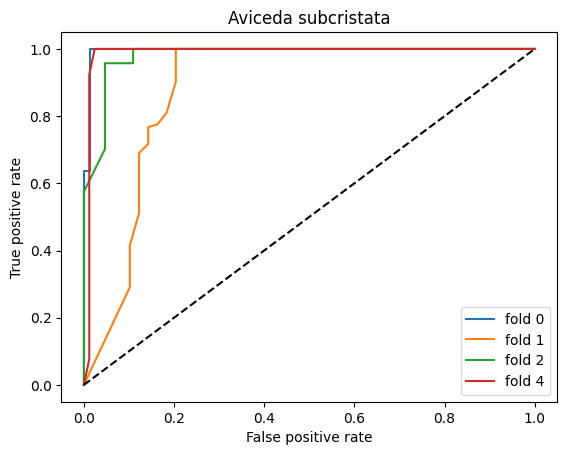

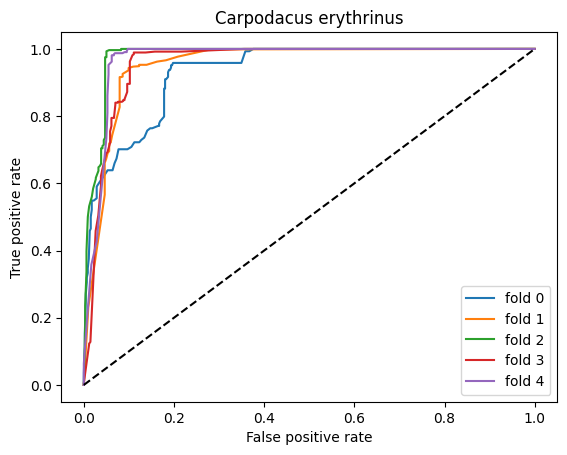

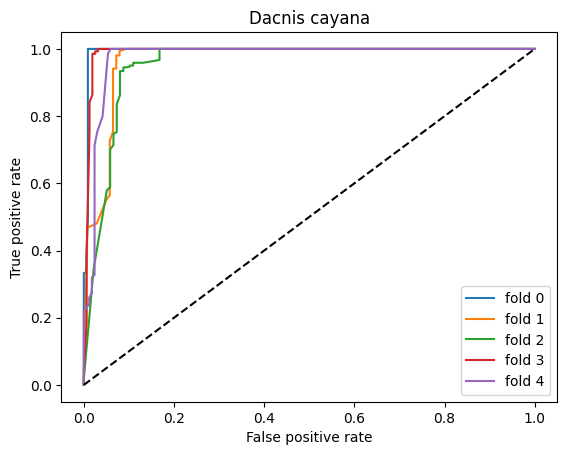

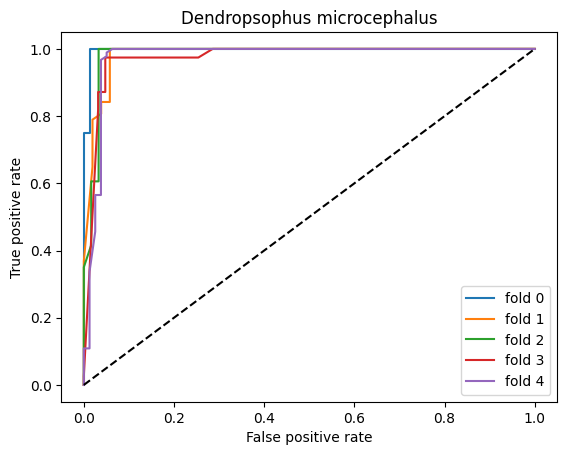

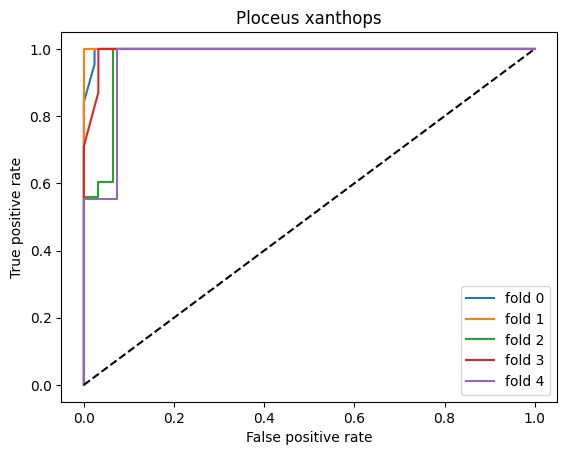

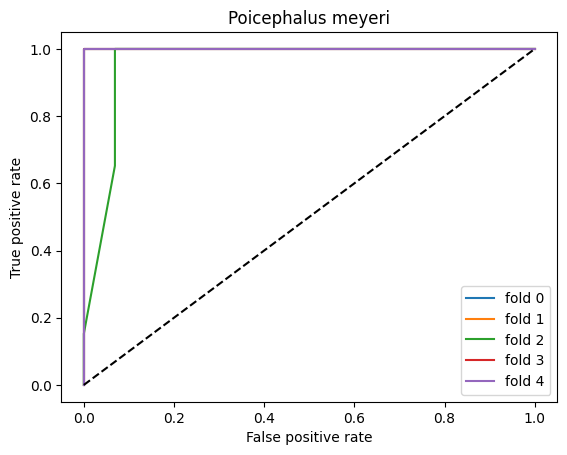

In [345]:
preds_rf = pd.read_csv('results/preds_rf.csv')

for spcs in species:
    d_sp = preds_rf[preds_rf['species'] == spcs]

    plt.figure()
    for fold in range(5):
        d = d_sp[d_sp['fold'] == fold]
        if len(d) == 0:
            continue
        fpr, tpr, _ = roc_curve(d['y_true'], d['score'])
        plt.plot(fpr, tpr, label='fold ' + str(fold))

    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(spcs)
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.legend()
    plt.savefig('results/roc_' + spcs + '.png')
    plt.show()

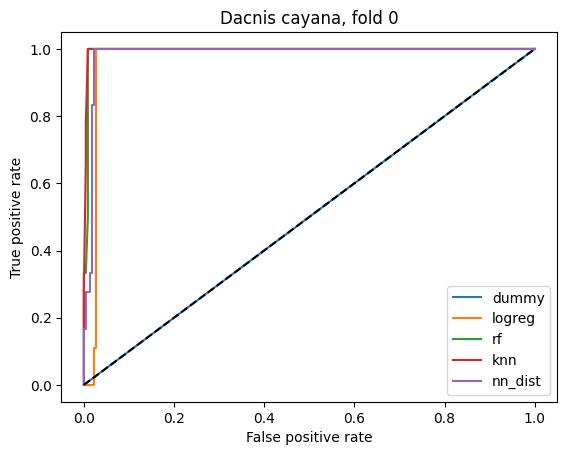

In [346]:
def draw(name, scores):
    fpr, tpr, _ = roc_curve(Y_test, scores)
    plt.plot(fpr, tpr, label=name)

res = split_fold(df_sel, 'Dacnis cayana', 0)
X_train, X_test, Y_train, Y_test = res

plt.figure()

for name, m in [('dummy', DummyClassifier(strategy='prior')),
                ('logreg', LogisticRegression(max_iter=1000)),
                ('rf', RandomForestClassifier(random_state=0)),
                ('knn', KNeighborsClassifier(n_neighbors=15))]:
    m.fit(X_train, Y_train)
    draw(name, m.predict_proba(X_test)[:, 1])

nn = NearestNeighbors(n_neighbors=1).fit(X_train[Y_train == 1])
draw('nn_dist', -nn.kneighbors(X_test)[0][:, 0])
plt.title('Dacnis cayana, fold 0')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.plot([0, 1], [0, 1], 'k--')
plt.legend()
plt.savefig('results/roc_models_dacnis_fold0.png')
plt.show()

In [347]:
res_all = pd.concat([res_dummy, res_nn, res_logreg, res_rf, knn_results, res_nested])
res_all.to_csv('results/all_models.csv', index=False)

In [348]:
print(len(res_all))

174


In [349]:
no_dummy = res_all[res_all['model'] != 'dummy']
worst = no_dummy.sort_values('roc_auc').head(10)
print(worst)

                        species  fold       model   roc_auc   avg_prc  best_k
2           Aviceda subcristata     2         knn  0.611037  0.558367     NaN
16  Dendropsophus microcephalus     2      logreg  0.841570  0.828897     NaN
4         Carpodacus erythrinus     0     nn_dist  0.848214  0.694742     NaN
4         Carpodacus erythrinus     0         knn  0.862714  0.718281     NaN
11                Dacnis cayana     2     nn_dist  0.871080  0.896951     NaN
1           Aviceda subcristata     1          rf  0.883958  0.953140     NaN
1           Aviceda subcristata     1      logreg  0.896614  0.966919     NaN
1           Aviceda subcristata     1  knn_nested  0.900134  0.963505    30.0
17  Dendropsophus microcephalus     3      logreg  0.901913  0.707724     NaN
1           Aviceda subcristata     1         knn  0.905632  0.965397     NaN


In [350]:
res_all = res_all.drop(columns='best_k')

In [351]:
hard_folds = no_dummy.groupby(['species', 'fold'])['roc_auc'].mean().sort_values().head(8)
print(hard_folds)

species                      fold
Aviceda subcristata          1       0.901353
                             2       0.903590
Carpodacus erythrinus        0       0.908049
Dacnis cayana                2       0.929929
Dendropsophus microcephalus  2       0.946177
Carpodacus erythrinus        1       0.950543
                             3       0.954369
Dacnis cayana                1       0.956470
Name: roc_auc, dtype: float64


In [352]:
print(df11[['lat_block', 'lon_block', 'spatial_block']].head())

   lat_block  lon_block spatial_block
0         12          9          12_9
1         11          7          11_7
2         13         10         13_10
3         14         26         14_26
4          5         32          5_32


In [353]:
print(df11[['lat_block', 'lon_block']].dtypes)

lat_block    int64
lon_block    int64
dtype: object


In [354]:
sp = 'Dacnis cayana'

own = df11[(df11['name'] == sp) & (df11['label'] == 1)]
near = set()
for i in range(len(own)):
    a = own['lat_block'].iloc[i]
    b = own['lon_block'].iloc[i]
    for da in [-1, 0, 1]:
        for db in [-1, 0, 1]:
            near.add((a + da, b + db))

print(len(own), len(near))

825 45


In [355]:
others = df11[(df11['name'] != sp) & (df11['label'] == 1)]

keep = []
for i in range(len(others)):
    pair = (others['lat_block'].iloc[i], others['lon_block'].iloc[i])
    keep.append(pair in near)

cand = others[keep]
print(len(others), len(cand))

6086 870


In [356]:
own_pts = set(zip(own['lat'], own['lon']))

keep2 = []
for i in range(len(cand)):
    pt = (cand['lat'].iloc[i], cand['lon'].iloc[i])
    keep2.append(pt not in own_pts)

cand2 = cand[keep2]
print(len(cand), len(cand2))

870 868


In [357]:
n = min(len(own), len(cand2))
neg = cand2.sample(n=n, random_state=0).copy()
neg['label'] = 0
print(len(own), len(neg))

825 825


In [358]:
neg['name'] = sp
hard_sp = pd.concat([own, neg])
print(hard_sp['label'].value_counts())
print(hard_sp['fold_id'].value_counts())


label
1    825
0    825
Name: count, dtype: int64
fold_id
3    638
2    513
4    265
1    209
0     25
Name: count, dtype: int64


In [359]:
enhanced = []

for sp in species:
    own = df11[(df11['name'] == sp) & (df11['label'] == 1)]

    near = set()
    for i in range(len(own)):
        a = own['lat_block'].iloc[i]
        b = own['lon_block'].iloc[i]
        for da in [-1, 0, 1]:
            for db in [-1, 0, 1]:
                new_b = b + db
                if new_b < 0:
                    new_b = 35
                if new_b > 35:
                    new_b = 0
                near.add((a + da, new_b))
    others = df11[(df11['name'] != sp) & (df11['label'] == 1)]
    keep = []
    for i in range(len(others)):
        pair = (others['lat_block'].iloc[i], others['lon_block'].iloc[i])
        keep.append(pair in near)
    cand = others[keep]

    own_pts = set()
    for i in range(len(own)):
        own_pts.add((own['lat'].iloc[i], own['lon'].iloc[i]))

    keep2 = []
    for i in range(len(cand)):
        pt = (cand['lat'].iloc[i], cand['lon'].iloc[i])
        keep2.append(pt not in own_pts)
    cand2 = cand[keep2]

    n = min(len(own), len(cand2))
    neg = cand2.sample(n=n, random_state=0).copy()
    neg['label'] = 0
    neg['name'] = sp
    enhanced.append(pd.concat([own, neg]))
    print(sp, len(own), len(near), len(cand2), n)

df_hard = pd.concat(enhanced)
print(df_hard.groupby(['name', 'label']).size())

Aviceda subcristata 329 30 86 86
Carpodacus erythrinus 1859 136 989 989
Dacnis cayana 825 45 868 825
Dendropsophus microcephalus 329 33 2124 329
Ploceus xanthops 172 27 198 172
Poicephalus meyeri 145 27 225 145
name                         label
Aviceda subcristata          0          86
                             1         329
Carpodacus erythrinus        0         989
                             1        1859
Dacnis cayana                0         825
                             1         825
Dendropsophus microcephalus  0         329
                             1         329
Ploceus xanthops             0         172
                             1         172
Poicephalus meyeri           0         145
                             1         145
dtype: int64


In [360]:
hard_lg = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_hard, spcs, fold)
        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            model = LogisticRegression(max_iter=1000, random_state=0)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            hard_lg.append({'species': spcs, 'fold': fold, 'model': 'logreg_hard',
                            'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_hard_lg = pd.DataFrame(hard_lg)
print(len(res_hard_lg))
print(res_hard_lg.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 0 skipped
Aviceda subcristata 3 skipped
28
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.702128  0.952061
Carpodacus erythrinus        0.964993  0.995810
Dacnis cayana                0.744432  0.832076
Dendropsophus microcephalus  0.583143  0.683135
Ploceus xanthops             0.606477  0.674057
Poicephalus meyeri           0.548390  0.614166


In [361]:
hard_rf = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_hard, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res

            model = RandomForestClassifier(n_estimators=100, random_state=0)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)

            hard_rf.append({'species': spcs, 'fold': fold, 'model': 'rf_hard',
                            'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_hard_rf = pd.DataFrame(hard_rf)
print(len(res_hard_rf))
print(res_hard_rf.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 0 skipped
Aviceda subcristata 3 skipped
28
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.721897  0.955891
Carpodacus erythrinus        0.994270  0.998308
Dacnis cayana                0.903948  0.928728
Dendropsophus microcephalus  0.775621  0.790835
Ploceus xanthops             0.443707  0.568931
Poicephalus meyeri           0.531671  0.619314


In [362]:
hard_knn = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_hard, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res
            model = KNeighborsClassifier(n_neighbors=15)
            model.fit(X_train, Y_train)
            scores = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)
            hard_knn.append({'species': spcs, 'fold': fold, 'model': 'knn15_hard',
                             'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_hard_knn = pd.DataFrame(hard_knn)
print(len(res_hard_knn))
print(res_hard_knn.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 0 skipped
Aviceda subcristata 3 skipped
28
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.688130  0.907360
Carpodacus erythrinus        0.997002  0.999265
Dacnis cayana                0.779548  0.879849
Dendropsophus microcephalus  0.757443  0.765406
Ploceus xanthops             0.486651  0.564465
Poicephalus meyeri           0.476980  0.605249


In [363]:
hard_nn = []

for spcs in species:
    for fold in range(5):
        res = split_fold(df_hard, spcs, fold)

        if res is None:
            print(spcs, fold, 'skipped')
        else:
            X_train, X_test, Y_train, Y_test = res

            X_pres = X_train[Y_train == 1]
            nn = NearestNeighbors(n_neighbors=1)
            nn.fit(X_pres)
            dist, _ = nn.kneighbors(X_test)
            scores = -dist[:, 0]
            roc_auc = roc_auc_score(Y_test, scores)
            avg_prc = average_precision_score(Y_test, scores)

            hard_nn.append({'species': spcs, 'fold': fold, 'model': 'nn_dist_hard',
                            'roc_auc': roc_auc, 'avg_prc': avg_prc})

res_hard_nn = pd.DataFrame(hard_nn)
print(len(res_hard_nn))
print(res_hard_nn.groupby('species')[['roc_auc', 'avg_prc']].mean())

Aviceda subcristata 0 skipped
Aviceda subcristata 3 skipped
28
                              roc_auc   avg_prc
species                                        
Aviceda subcristata          0.978465  0.949749
Carpodacus erythrinus        0.855195  0.960802
Dacnis cayana                0.571428  0.719148
Dendropsophus microcephalus  0.803498  0.889346
Ploceus xanthops             0.432964  0.572623
Poicephalus meyeri           0.659542  0.632632


In [364]:
res_hard = pd.concat([res_hard_lg, res_hard_rf, res_hard_knn, res_hard_nn])
print(len(res_hard))

112


In [365]:
print(res_hard.groupby(['species', 'model'])['roc_auc'].mean().unstack())

model                        knn15_hard  logreg_hard  nn_dist_hard   rf_hard
species                                                                     
Aviceda subcristata            0.688130     0.702128      0.978465  0.721897
Carpodacus erythrinus          0.997002     0.964993      0.855195  0.994270
Dacnis cayana                  0.779548     0.744432      0.571428  0.903948
Dendropsophus microcephalus    0.757443     0.583143      0.803498  0.775621
Ploceus xanthops               0.486651     0.606477      0.432964  0.443707
Poicephalus meyeri             0.476980     0.548390      0.659542  0.531671


In [366]:
res_hard.to_csv('results/hard_negatives.csv', index=False)

In [367]:
knn_k15 = pd.read_csv('results/knn_k15.csv')

main = pd.concat([res_dummy, res_nn, res_logreg, res_rf,
                  knn_results, knn_k15, res_nested])
main = main.drop(columns='best_k')
main['setting'] = 'main'

hard = res_hard.copy()
hard['setting'] = 'hard_negatives'

final_all = pd.concat([main, hard], ignore_index=True)
print(len(final_all))
print(final_all.groupby(['setting', 'model']).size())

final_all.to_csv('results/all_models_final.csv', index=False)

315
setting         model       
hard_negatives  knn15_hard      28
                logreg_hard     28
                nn_dist_hard    28
                rf_hard         28
main            dummy           29
                knn             29
                knn_k15         29
                knn_nested      29
                logreg          29
                nn_dist         29
                rf              29
dtype: int64


In [368]:
print(len(res_tune))
print(knn_k15.duplicated(subset=['species', 'fold']).sum())

145
0


In [369]:
knn_k15 = knn_k15.drop_duplicates(subset=['species', 'fold'])
print(len(knn_k15))       

29


In [370]:
knn_k15.to_csv('results/knn_k15.csv', index=False)

In [371]:
summary = final_all.groupby(['setting', 'model'])[['roc_auc', 'avg_prc']].agg(['mean', 'std'])
print(summary)

                              roc_auc             avg_prc          
                                 mean       std      mean       std
setting        model                                               
hard_negatives knn15_hard    0.698304  0.277011  0.778331  0.232426
               logreg_hard   0.690841  0.279041  0.780443  0.197214
               nn_dist_hard  0.698162  0.255404  0.775786  0.206840
               rf_hard       0.728992  0.264745  0.799938  0.236848
main           dummy         0.500000  0.000000  0.446600  0.203248
               knn           0.954725  0.073618  0.921539  0.092640
               knn_k15       0.972480  0.023761  0.944266  0.047573
               knn_nested    0.971408  0.023069  0.941133  0.049419
               logreg        0.958698  0.035103  0.900538  0.109894
               nn_dist       0.964579  0.037865  0.922447  0.120361
               rf            0.976651  0.025069  0.959161  0.043258


In [372]:
res_hard[res_hard['species']=='Ploceus xanthops'][['fold','model','roc_auc']]

,fold,model,roc_auc
18,0,logreg_hard,0.717295
19,1,logreg_hard,0.797619
20,2,logreg_hard,0.261695
21,3,logreg_hard,0.709677
22,4,logreg_hard,0.546099
18,0,rf_hard,0.575388
19,1,rf_hard,0.398810
20,2,rf_hard,0.270783
21,3,rf_hard,0.280645
22,4,rf_hard,0.692908


In [373]:
import os
print(os.getcwd())

/home/nikta/AML/project/AML_coursework/phase3
